In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [14]:
FILE = 'keis.xlsx'
df_users = pd.read_excel(FILE, sheet_name='Пользователи')
df_payments = pd.read_excel(FILE, sheet_name='Платежи')

print(f"Пользователи: {df_users.shape}, Платежи: {df_payments.shape}")

Пользователи: (1504, 5), Платежи: (2661, 7)


In [15]:
# Пользователи: убираем без группы, без города и с аномальным возрастом
df_users = df_users.dropna(subset=['group', 'city'])
df_users = df_users[(df_users['age'] >= 0) & (df_users['age'] <= 100)]
print(f"Пользователей после очистки: {len(df_users)}")
print(df_users['group'].value_counts())

# Платежи: убираем без user_id, оставляем только от валидных пользователей
df_payments = df_payments.dropna(subset=['user_id'])
df_payments['user_id'] = df_payments['user_id'].astype(int)
df_payments = df_payments[df_payments['user_id'].isin(df_users['user_id'])]
# Заменяем group из платежей на группу из пользователей (источник истины — users)
df_payments = df_payments.drop(columns='group').merge(
    df_users[['user_id', 'group']], on='user_id', how='left'
)
print(f"Платежей после очистки: {len(df_payments)}")
print(df_payments['group'].value_counts())

Пользователей после очистки: 1500
group
A    750
B    750
Name: count, dtype: int64
Платежей после очистки: 2659
group
B    1351
A    1308
Name: count, dtype: int64


In [16]:
user_agg = df_payments.groupby('user_id').agg(
    group=('group', 'first'),
    attempts=('payment_id', 'count'),
    has_step2=('step2_entered', lambda x: x.notna().any()),
    has_step3=('step3_confirmed', lambda x: x.notna().any()),
    has_success=('step4_success', lambda x: x.notna().any())
).reset_index()

user_agg = user_agg.merge(
    df_users[['user_id', 'device_type', 'city', 'age']], on='user_id', how='left'
)

### Конверсия

In [17]:
conv = user_agg.groupby('group').agg(
    total=('user_id', 'count'),
    step2=('has_step2', 'sum'),
    step3=('has_step3', 'sum'),
    success=('has_success', 'sum')
).reset_index()

conv['conv_1_2'] = conv['step2'] / conv['total']
conv['conv_2_3'] = conv['step3'] / conv['step2']
conv['conv_3_4'] = conv['success'] / conv['step3']
conv['conv_1_4'] = conv['success'] / conv['total']

print(conv[['group', 'total', 'success', 'conv_1_4']])

conv_a = conv.loc[conv['group'] == 'A', 'conv_1_4'].iloc[0]
conv_b = conv.loc[conv['group'] == 'B', 'conv_1_4'].iloc[0]
n_a = conv.loc[conv['group'] == 'A', 'total'].iloc[0]
n_b = conv.loc[conv['group'] == 'B', 'total'].iloc[0]
succ_a = conv.loc[conv['group'] == 'A', 'success'].iloc[0]
succ_b = conv.loc[conv['group'] == 'B', 'success'].iloc[0]

  group  total  success  conv_1_4
0     A    750      493  0.657333
1     B    750      603  0.804000


### Статистический тест

In [18]:
z_stat, p_value = proportions_ztest(
    count=[succ_b, succ_a], nobs=[n_b, n_a], alternative='larger'
)

se = np.sqrt(conv_a*(1-conv_a)/n_a + conv_b*(1-conv_b)/n_b)
diff = conv_b - conv_a
ci_lower, ci_upper = diff - 1.96*se, diff + 1.96*se
lift = (conv_b / conv_a - 1) * 100

print(f"A: {conv_a:.2%} ({succ_a}/{n_a})")
print(f"B: {conv_b:.2%} ({succ_b}/{n_b})")
print(f"Разница: {diff:.2%}, Lift: {lift:.1f}%")
print(f"Z = {z_stat:.4f}, p = {p_value:.6f}")
print(f"95% CI: [{ci_lower:.2%}; {ci_upper:.2%}]")
print("Значимо" if p_value < 0.05 else "Не значимо")

A: 65.73% (493/750)
B: 80.40% (603/750)
Разница: 14.67%, Lift: 22.3%
Z = 6.4024, p = 0.000000
95% CI: [10.24%; 19.09%]
Значимо


### Визуализация

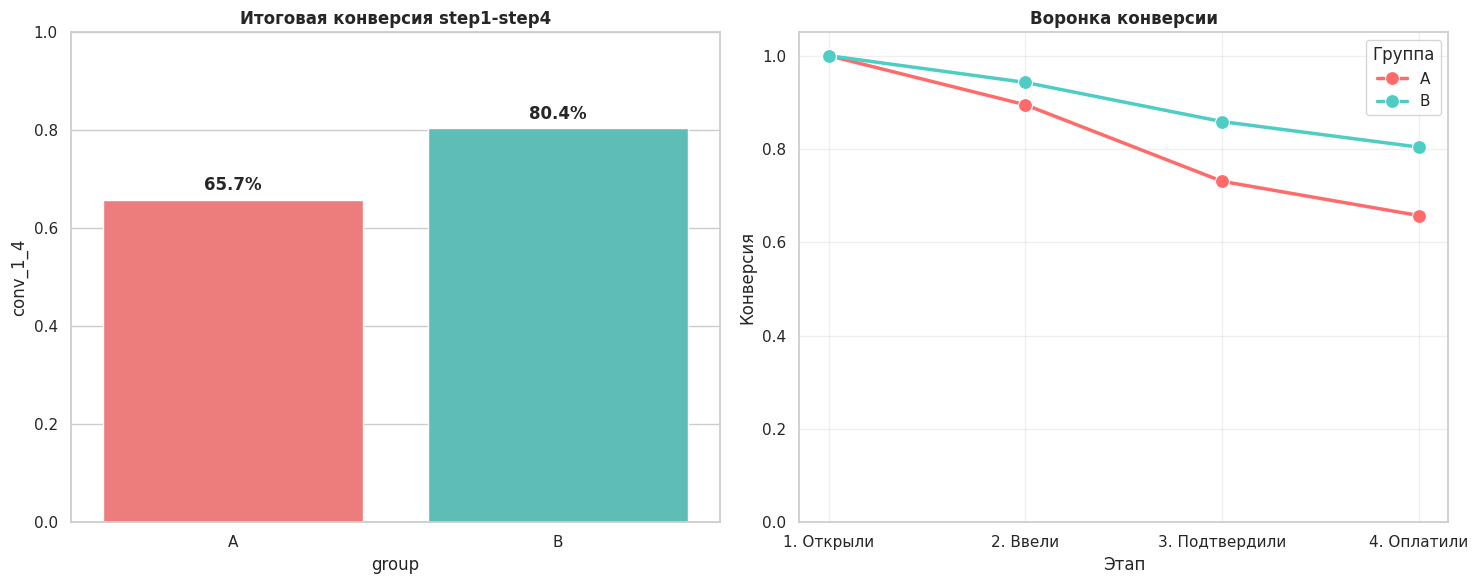

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Конверсия по группам
sns.barplot(data=conv, x='group', y='conv_1_4', palette=['#FF6B6B', '#4ECDC4'], ax=axes[0])
axes[0].set_title('Итоговая конверсия step1-step4', fontweight='bold')
axes[0].set_ylim(0, 1)
for i, row in conv.iterrows():
    axes[0].text(i, row['conv_1_4'] + 0.02, f"{row['conv_1_4']:.1%}", ha='center', fontweight='bold')

# Воронка
funnel = []
for _, row in conv.iterrows():
    funnel.append({'Группа': row['group'], 'Этап': '1. Открыли', 'Конверсия': 1.0})
    funnel.append({'Группа': row['group'], 'Этап': '2. Ввели', 'Конверсия': row['conv_1_2']})
    funnel.append({'Группа': row['group'], 'Этап': '3. Подтвердили', 'Конверсия': row['conv_1_2']*row['conv_2_3']})
    funnel.append({'Группа': row['group'], 'Этап': '4. Оплатили', 'Конверсия': row['conv_1_4']})
funnel_df = pd.DataFrame(funnel)

sns.lineplot(data=funnel_df, x='Этап', y='Конверсия', hue='Группа',
             marker='o', linewidth=2.5, markersize=10,
             palette=['#FF6B6B', '#4ECDC4'], ax=axes[1])
axes[1].set_title('Воронка конверсии', fontweight='bold')
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Сегментный анализ

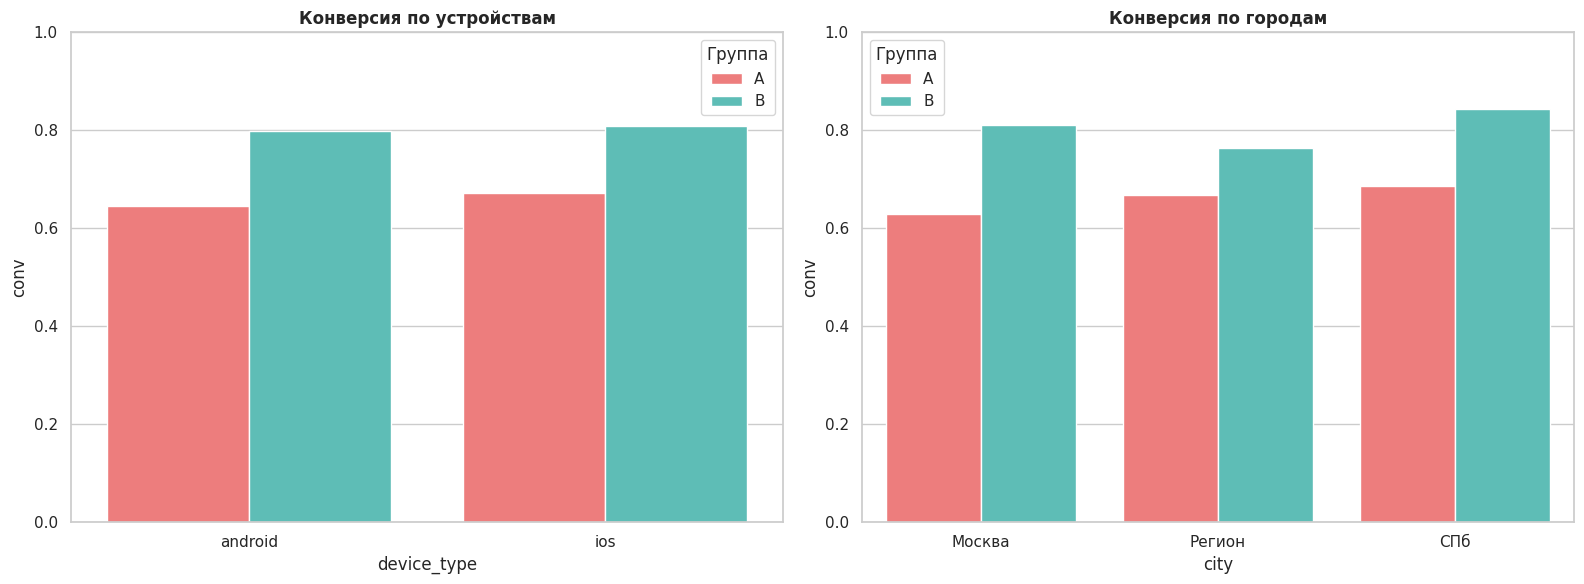

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# По устройствам
dev = user_agg.groupby(['group', 'device_type']).agg(
    total=('user_id', 'count'), success=('has_success', 'sum')
).reset_index()
dev['conv'] = dev['success'] / dev['total']

sns.barplot(data=dev, x='device_type', y='conv', hue='group',
            palette=['#FF6B6B', '#4ECDC4'], ax=axes[0])
axes[0].set_title('Конверсия по устройствам', fontweight='bold')
axes[0].set_ylim(0, 1)
axes[0].legend(title='Группа')

# По городам
city = user_agg.groupby(['group', 'city']).agg(
    total=('user_id', 'count'), success=('has_success', 'sum')
).reset_index()
city['conv'] = city['success'] / city['total']

sns.barplot(data=city, x='city', y='conv', hue='group',
            palette=['#FF6B6B', '#4ECDC4'], ax=axes[1])
axes[1].set_title('Конверсия по городам', fontweight='bold')
axes[1].set_ylim(0, 1)
axes[1].legend(title='Группа')

plt.tight_layout()
plt.show()

### Бизнес-эффект

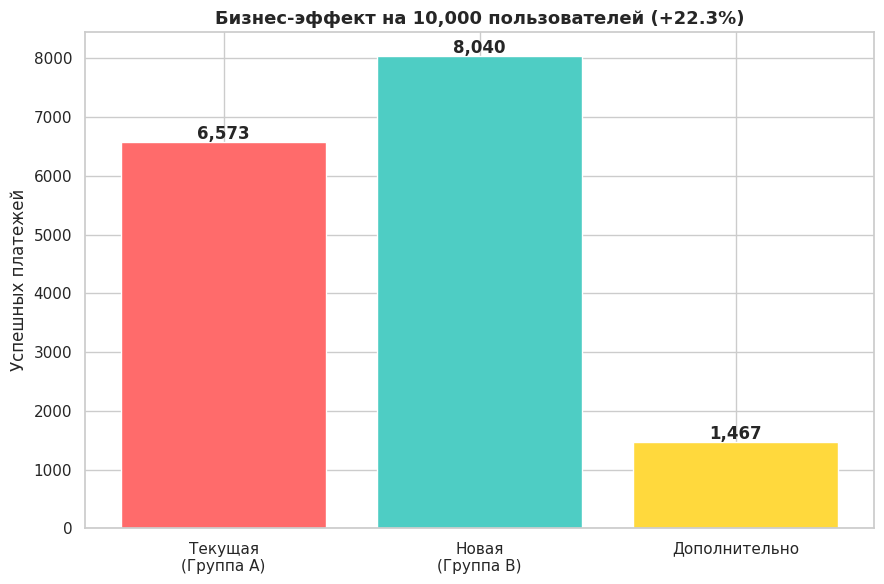

In [28]:
scale = 10000
cur = int(scale * conv_a)
new = int(scale * conv_b)
extra = new - cur

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(['Текущая\n(Группа A)', 'Новая\n(Группа B)', 'Дополнительно'],
              [cur, new, extra],
              color=['#FF6B6B', '#4ECDC4', '#FFD93D'])
for bar, val in zip(bars, [cur, new, extra]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val:,}', ha='center', fontweight='bold')
ax.set_title(f'Бизнес-эффект на {scale:,} пользователей (+{lift:.1f}%)',
             fontweight='bold', fontsize=13)
ax.set_ylabel('Успешных платежей')
plt.tight_layout()
plt.show()

## Выводы

Новая форма оплаты повышает итоговую конверсию с 65.7% до 80.4% (+14.7 п.п., +22.3% относительно), улучшение статистически значимо (p < 0.001), подтверждается на всех шагах воронки, рекомендация к полному раскатыванию.

## Рекомендации

1) Если данные собраны за короткий период, стоит убедиться в отсутствии эффекта новизны, возможно пользователи кликают чаще просто из-за непривычности интерфейса.
2) Конверсия выросла, но нужно проверить, не выросли ли отмены/возвраты/фрод-срабатывания в группе B.
3) Проверить ошибки на бэкенде, время ответа API, время загрузки формы. Не должно быть регрессии.